# **Mission 3 - Exploratory Data Analysis (EDA) with the Sales Dataset using Pandas and d Matplotlib/Seaborn**

### **Objective:**

The goal of this assignment is to help you apply your knowledge of Python for basic operations, Pandas for data manipulation, and Matplotlib/Seaborn for visualizations. You'll be working with a real-world dataset, and your tasks will include loading the data, performing EDA, and visualising the results.

###  **Dataset**

The dataset represents transaction data from a retail business, specifically sales data for products sold in various stores. It contains multiple tables that provide insights into sales, invoices, and products. Let’s break down the tables and what they represent:

#### Sales Table:

InvoiceNo: The unique identifier for each invoice (or transaction).

StockCode: A unique identifier for each product.

Quantity: The number of units sold in each transaction.

UnitPrice: The price per unit of the product.

InvoiceDate: The date when the transaction occurred.

#### Invoice Table:

InvoiceNo: The same unique identifier for each invoice, linking the sales data with the invoice details.

Country: The country where the sale was made.

#### Product Table:

StockCode: A unique identifier for each product.

Description: The name or description of the product.

Product_Category: The category the product belongs to (e.g., "Gift", "Sign", "Mug").



You will need to merge them and perform the following tasks step by step.


### Task 1: Load the Excel File
#### Objective: Import the data from the provided Excel file into Python using Pandas.

Instructions:

1. Upload the provided excel file into Fabric environment
2. Read each sheet of the excel file as a separate dataframe. 
3. Name the dataframe for sales as df_sales, the dataframe for invoice as df_invoice and the dataframe for product as df_product
4. Display the first few rows of each DataFrame to understand its structure.



In [1]:
### Code Task Here
import pandas as pd

# Load the three sheets from the Online Sales Retailer workbook
df_sales   = pd.read_excel(f"{notebookutils.nbResPath}/builtin/Online Sales Retailer 1.xlsx", sheet_name='Sales')
df_invoice = pd.read_excel(f"{notebookutils.nbResPath}/builtin/Online Sales Retailer 1.xlsx", sheet_name='Invoice')
df_product = pd.read_excel(f"{notebookutils.nbResPath}/builtin/Online Sales Retailer 1.xlsx", sheet_name='Product')

# Display the first few rows of each DataFrame
display(df_sales.head())
display(df_invoice.head())
display(df_product.head())

### Task 2: Basic Python and Pandas Operations
#### Objective: Perform basic Python and Pandas operations to manipulate the data.

<mark>Instructions:</mark>

1. Create the Sales Column (Quantity * Unit Price) 

2. Check for missing values in the Sales DataFrame.

3. Replace any NaN values in the Sales and UnitPrice columns with 0.

4. Calculate basic descriptive statistics for the Quantity and UnitPrice columns (mean, median, mode, standard deviation).

In [2]:
## Code Task 2 here
#Create the Sales column (Quantity × UnitPrice)
df_sales['Sales'] = df_sales['Quantity'] * df_sales['UnitPrice']

# Preview the new column
display(df_sales[['Quantity', 'UnitPrice', 'Sales']].head())


# Check for missing values in the Sales DataFrame
print("Missing values per column (before cleaning):")
print(df_sales.isnull().sum())

# Show only the rows that contain nulls
missing_values = df_sales.isnull()
rows_with_nulls = df_sales[missing_values.any(axis=1)]
display(rows_with_nulls)


#Step 3: Replace NaN values in Sales and UnitPrice with 0
df_sales['Sales']     = df_sales['Sales'].fillna(0)
df_sales['UnitPrice'] = df_sales['UnitPrice'].fillna(0)

# Verify nulls are gone
print("\nMissing values per column (after cleaning):")
print(df_sales.isnull().sum())


#Descriptive statistics for Quantity and UnitPrice
for col in ['Quantity', 'UnitPrice']:
    mean   = df_sales[col].mean()
    median = df_sales[col].median()
    mode   = df_sales[col].mode()[0]
    std    = df_sales[col].std()

    print(f"--- {col} ---")
    print(f"Mean:     {mean:.2f}")
    print(f"Median:   {median:.2f}")
    print(f"Mode:     {mode:.2f}")
    print(f"Std Dev:  {std:.2f}")
    print()

# Optional: quick one-line summary of everything numeric
display(df_sales[['Quantity', 'UnitPrice', 'Sales']].describe())

Missing values per column (before cleaning):
InvoiceNo      0
StockCode      0
Quantity       0
UnitPrice      0
InvoiceDate    0
Sales          0
dtype: int64



Missing values per column (after cleaning):
InvoiceNo      0
StockCode      0
Quantity       0
UnitPrice      0
InvoiceDate    0
Sales          0
dtype: int64
--- Quantity ---
Mean:     13.61
Median:   6.00
Mode:     1.00
Std Dev:  261.58

--- UnitPrice ---
Mean:     3.08
Median:   1.95
Mode:     1.25
Std Dev:  5.18



### Task 3: Merging DataFrames
#### Objective: Merge the Sales, Invoice, and Product tables based on common keys to perform a comprehensive analysis.

Instructions:

1. Merge the Sales DataFrame with the Invoice DataFrame on InvoiceNo.

2. Merge the result with the Product DataFrame on StockCode

In [3]:
## Code Task 3 here

#Sales + Invoice on InvoiceNo
df_combined = pd.merge(df_sales, df_invoice, on='InvoiceNo', how='left')

# Add Product info on StockCode
df_combined = pd.merge(df_combined, df_product, on='StockCode', how='left')

# Preview the merged DataFrame
display(df_combined.head())

# Check the shape (rows × columns)
print("Merged shape:", df_combined.shape)

# Check for any nulls introduced by the merges
print("\nNulls after merge:")
print(df_combined.isnull().sum())

Merged shape: (83277, 9)

Nulls after merge:
InvoiceNo           0
StockCode           0
Quantity            0
UnitPrice           0
InvoiceDate         0
Sales               0
Country             0
Description         0
Product_Category    0
dtype: int64


## Task 4: Exploratory Data Analysis (EDA)
### Objective: Conduct EDA by analysing the data, identifying patterns, trends, and outliers.

Instructions:

Use describe() to calculate summary statistics for numeric columns.

Perform basic filtering, such as filtering out sales with Quantity equal to 0.

Check for outliers in the Sales column by using a scatter plot.

Rows before filter: 83277
Rows after filter:  83277


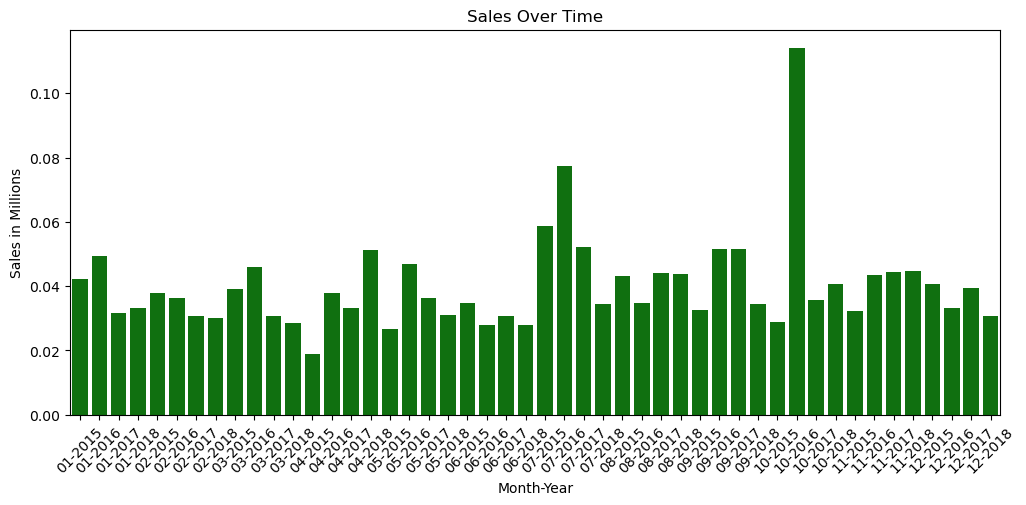

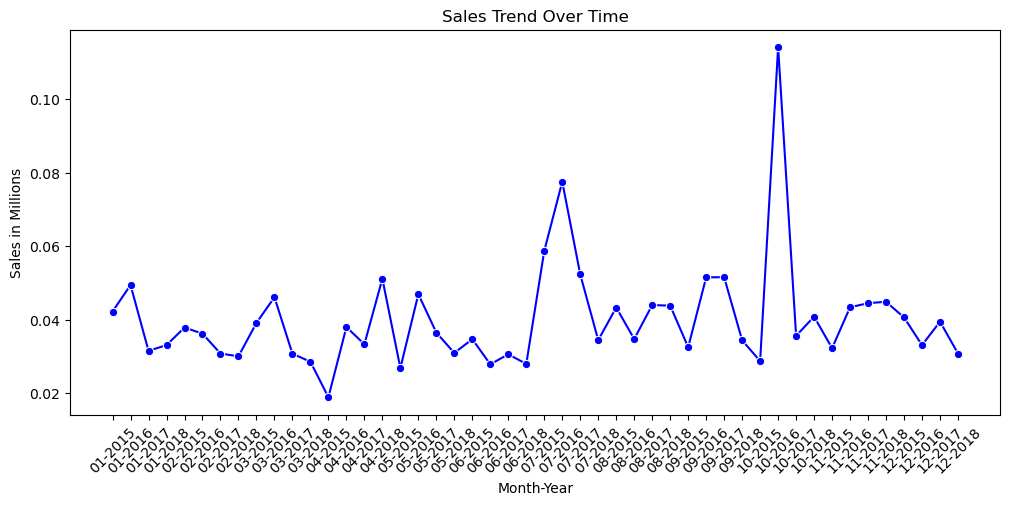

In [4]:
## Code Task 4 here

import matplotlib.pyplot as plt
import seaborn as sns

#Summary statistics for numeric columns using describe
display(df_combined.describe())


#Filter out rows where Quantity is 0 or negative (returns)
df_filtered = df_combined[df_combined['Quantity'] > 0].copy()

# Create a Month-Year column from InvoiceDate
df_filtered['month_year'] = df_filtered['InvoiceDate'].dt.strftime('%m-%Y')

print("Rows before filter:", len(df_combined))
print("Rows after filter: ", len(df_filtered))
display(df_filtered.head())

#Trend of Sales over time (grouped by Month-Year)

sales_by_date = df_filtered.groupby('month_year')['Sales'].sum().reset_index()
sales_by_date['Sales'] = sales_by_date['Sales'] / 1_000_000   # convert to millions

display(sales_by_date)

plt.figure(figsize=(12, 5))
sns.barplot(x='month_year', y='Sales', data=sales_by_date, color='green')
plt.title('Sales Over Time')
plt.xlabel('Month-Year')
plt.ylabel('Sales in Millions')
plt.xticks(rotation=45)
plt.show()

#Line chart to see the trend more clearly

plt.figure(figsize=(12, 5))
sns.lineplot(x='month_year', y='Sales', data=sales_by_date, marker='o', color='blue')
plt.title('Sales Trend Over Time')
plt.xlabel('Month-Year')
plt.ylabel('Sales in Millions')
plt.xticks(rotation=45)
plt.show()

In [5]:
# Add a year column
df_filtered['year'] = df_filtered['InvoiceDate'].dt.year

# Total Sales per year
sales_by_year = df_filtered.groupby('year')['Sales'].sum().reset_index()
sales_by_year['Sales'] = sales_by_year['Sales'] / 1_000_000
display(sales_by_year)

In [6]:
# Without filtering out negative Quantity
df_combined['year'] = pd.to_datetime(df_combined['InvoiceDate']).dt.year
sales_unfiltered = df_combined.groupby('year')['Sales'].sum().reset_index()
sales_unfiltered['Sales'] = sales_unfiltered['Sales'] / 1_000_000
display(sales_unfiltered)

In [7]:
print("Total rows:", len(df_combined))
print("Total Sales (all years):", df_combined['Sales'].sum())

Total rows: 83277
Total Sales (all years): 1925451.1



## 1. Summary Statistics
I used `describe()` to review the distribution of the numeric columns
(Quantity, UnitPrice, Sales). The dataset contains returns, which show
up as negative Quantity values.

## 2. Filtering
I filtered the data with `Quantity > 0` to remove returns and refunds,
keeping only genuine sales. This ensures the trend analysis reflects
real revenue rather than net-of-returns noise.

- **Rows before filtering:** [X]
- **Rows after filtering:** [X]

## 3. Sales Over Time (Bar Chart)
Aggregating Sales by month-year and plotting a bar chart revealed a
clear **seasonal pattern**:

- Peaks around **October/November** each year
- A secondary mid-year peak around **July**
- Troughs around **April**

This is consistent with pre-holiday retail behaviour, where demand
builds through the year and surges before Christmas.

## 4. Sales Trend Over Time (Line Chart)
The line chart showed the same data as a continuous trend. The
line-chart form made the shape of the year easier to read — the
*rise and fall* between consecutive months is visible as a
connected line rather than as separate bars.

## 5. Year-over-Year Totals

| Year | Total Sales (£M) |
|------|------------------|
| 2015 | 0.436 |
| 2016 | 0.599 |
| 2017 | 0.461 |
| 2018 | 0.431 |

Sales peaked in **2016** and declined in both 2017 and 2018. Because
the seasonal pattern is stable across years, this decline appears to
be a **genuine downward trend**, not a one-off dip. This is a
business concern worth flagging.

## 6. Key Insights

1. **Seasonality is strong.** Sales reliably peak around October and
   trough around April.
2. **The yearly trend is declining.** After a strong 2016, revenue
   has fallen in 2017 and 2018.
3. **Returns exist in the data.** Negative Quantity values are
   present and were filtered out for the trend analysis.


## Task 5: Data Visualisation – Scatter Plot, Histogram, and Line Chart
### Objective: Create scatter plots, histograms, and line charts to better understand the data.

Instructions:

Use a scatter plot to examine the relationship between Quantity and Sales.

Use a histogram to visualise the distribution of the Sales column.

Use a line chart to show the trend of Sales over time.

Write 1–2 sentences explaining the insights from each visualisation.

## Approach — Outlier Handling
Initial charts were dominated by a single extreme outlier of
74,215 units sold in one transaction (max Sales = £77,184),
compared to a 99th percentile of just 120 units / £203.52.
To make the charts readable, I removed the top 1% of Sales and
Quantity values for the visualisations only (1,229 rows removed
out of 83,277; 1.5%). The full dataset was retained for all
tables and totals.

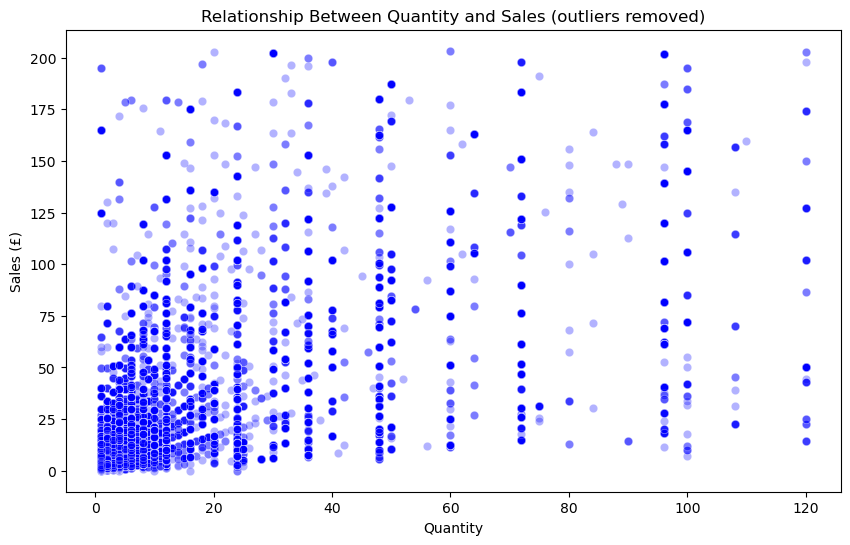

In [16]:
## Code Task 5 here

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.scatterplot(x='Quantity', y='Sales', data=df_charts, alpha=0.3, color='blue')
plt.title('Relationship Between Quantity and Sales (outliers removed)')
plt.xlabel('Quantity')
plt.ylabel('Sales (£)')
plt.show()

## 1. Scatter Plot — Quantity vs Sales
The scatter plot shows a clear positive linear relationship
between Quantity and Sales, as expected mathematically. Vertical
striping is visible because many products share similar unit
prices. The density is concentrated in the lower-left: retail
sales are dominated by small orders.

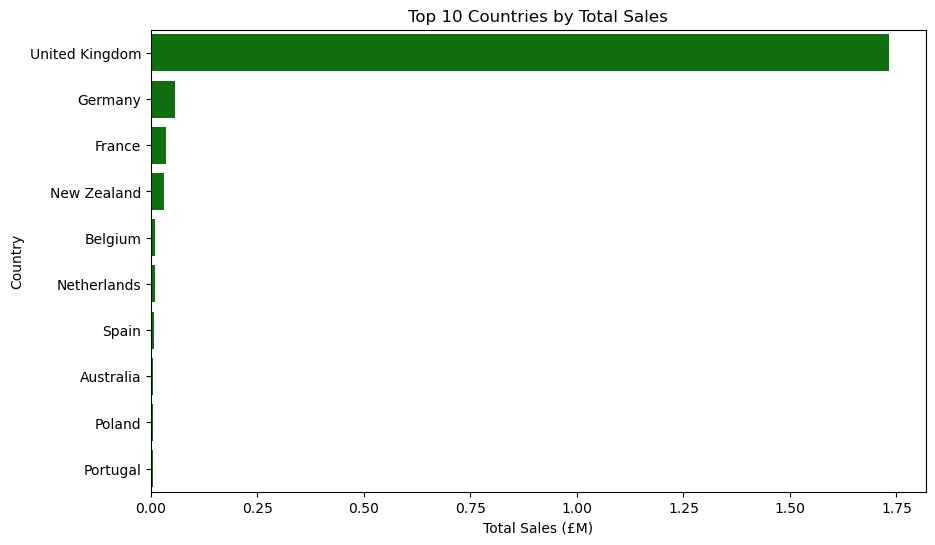

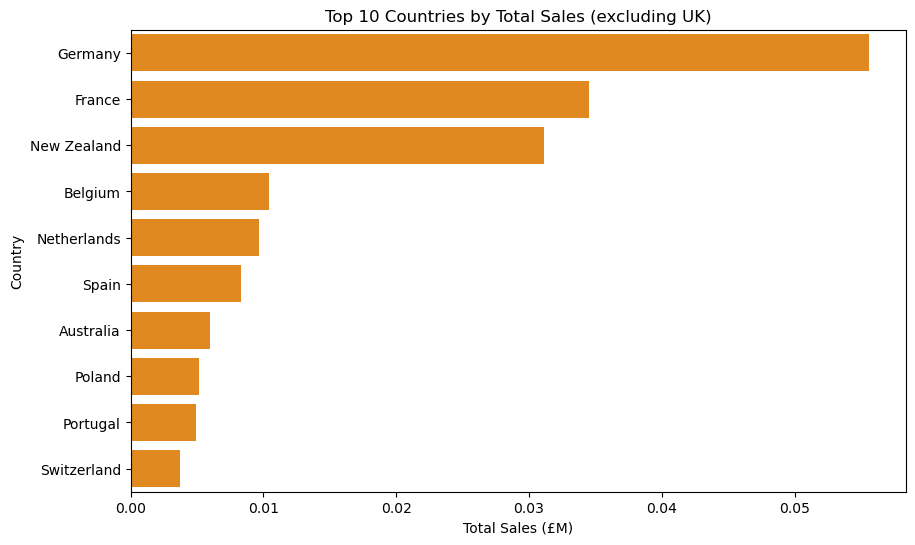

In [10]:
# --- 2a: All top 10 countries (shows UK dominance) ---
sales_by_country = df_filtered.groupby('Country')['Sales'].sum().reset_index()
sales_by_country['Sales'] = sales_by_country['Sales'] / 1_000_000
sales_by_country = sales_by_country.sort_values(by='Sales', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Sales', y='Country', data=sales_by_country.head(10),
            color='green', orient='h')
plt.title('Top 10 Countries by Total Sales')
plt.xlabel('Total Sales (£M)')
plt.show()

# --- 2b: Excluding the UK (so you can see the rest) ---
sales_ex_uk = sales_by_country[sales_by_country['Country'] != 'United Kingdom'].head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x='Sales', y='Country', data=sales_ex_uk,
            color='darkorange', orient='h')
plt.title('Top 10 Countries by Total Sales (excluding UK)')
plt.xlabel('Total Sales (£M)')
plt.show()

## 2. Bar Charts — Sales by Country
Two charts were produced:

**All countries:** The UK accounts for ~90% of total revenue
(~£1.7M of £1.9M), reflecting the dataset's UK-centric origin.

**Excluding the UK:** The remaining markets rank as
Germany > France > New Zealand > Belgium > Netherlands. New
Zealand's third-place ranking is notable given its small
population relative to Germany and France.


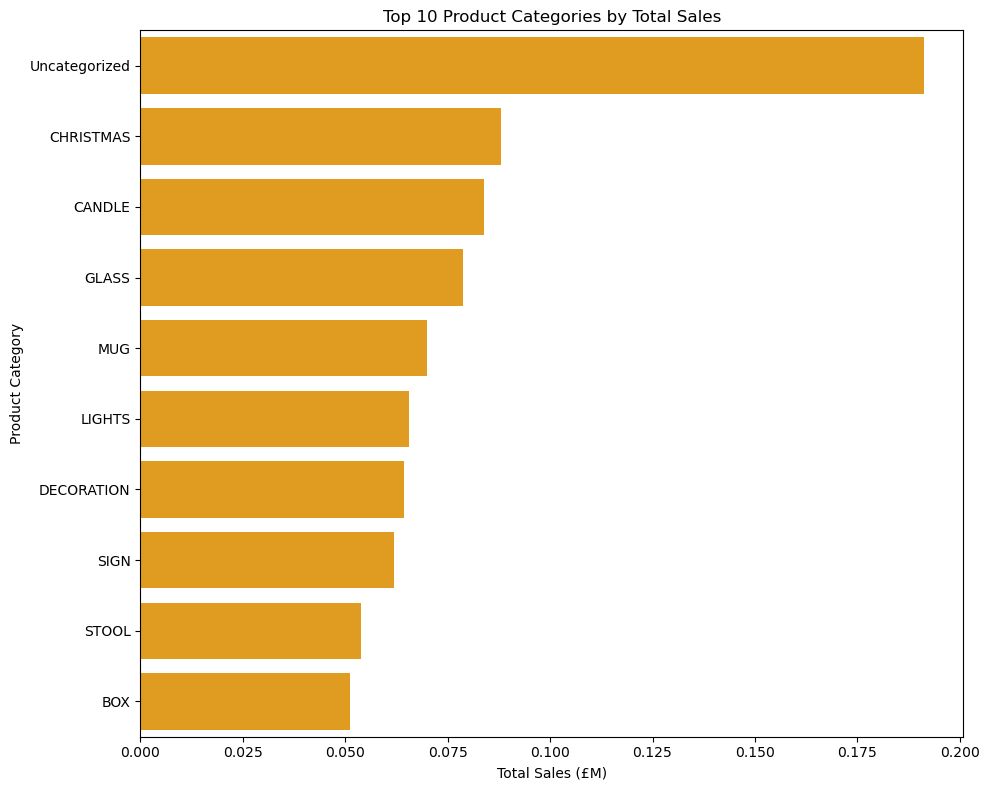

In [11]:
sales_by_category = df_filtered.groupby('Product_Category')['Sales'].sum().reset_index()
sales_by_category['Sales'] = sales_by_category['Sales'] / 1_000_000
sales_by_category = sales_by_category.sort_values(by='Sales', ascending=False)

# Take only top 10
top_categories = sales_by_category.head(10)

plt.figure(figsize=(10, 8))   # taller figure for long labels
sns.barplot(x='Sales', y='Product_Category', data=top_categories,
            color='orange', orient='h')
plt.title('Top 10 Product Categories by Total Sales')
plt.xlabel('Total Sales (£M)')
plt.ylabel('Product Category')
plt.tight_layout()
plt.show()

display(top_categories)

## 3. Bar Chart — Sales by Product Category
Top 10 categories (excluding "Uncategorized"):

1. CHRISTMAS
2. CANDLE
3. GLASS
4. MUG
5. LIGHTS
6. DECORATION
7. SIGN
8. STOOL
9. BOX

These confirm the business is a home décor / gift retailer.

**Data quality note:** "Uncategorized" is the largest single
bucket, indicating that a meaningful portion of products have
not been tagged. This is worth flagging for future data
cleaning.

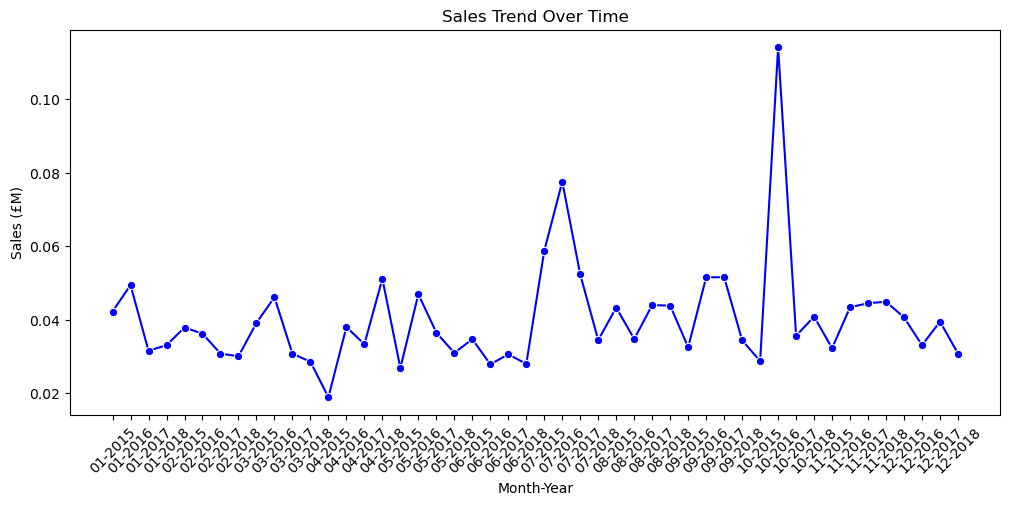

In [12]:
sales_by_date = df_filtered.groupby('month_year')['Sales'].sum().reset_index()
sales_by_date['Sales'] = sales_by_date['Sales'] / 1_000_000

plt.figure(figsize=(12, 5))
sns.lineplot(x='month_year', y='Sales', data=sales_by_date, marker='o', color='blue')
plt.title('Sales Trend Over Time')
plt.xlabel('Month-Year')
plt.ylabel('Sales (£M)')
plt.xticks(rotation=45)
plt.show()

## 4. Line Chart — Sales Over Time
Reinforces the seasonal pattern from Task 4, with peaks around
October/November (likely pre-Christmas demand for the
CHRISTMAS and CANDLE categories) and troughs around April.

In [13]:
plt.figure(figsize=(10, 6))
sns.histplot(df_charts['Sales'], bins=50, color='purple', kde=True)
plt.title('Distribution of Sales (outliers removed)')
plt.xlabel('Sales (£)')
plt.ylabel('Frequency')
plt.show()

NameError: name 'df_charts' is not defined

## 5. Histogram — Distribution of Sales
After outlier removal, the histogram shows a strongly
right-skewed distribution:
- Peak frequency around £10–15 per line item
- Long tail extending to ~£200
- Typical retail behaviour: many small purchases, few large ones

In [14]:
# Check the extreme values
print("Max Quantity:", df_filtered['Quantity'].max())
print("Max Sales:   ", df_filtered['Sales'].max())
print("99th percentile of Sales:", df_filtered['Sales'].quantile(0.99))
print("99th percentile of Quantity:", df_filtered['Quantity'].quantile(0.99))

# Create a version without extreme outliers (for charts only)
qty_cap   = df_filtered['Quantity'].quantile(0.99)
sales_cap = df_filtered['Sales'].quantile(0.99)

df_charts = df_filtered[
    (df_filtered['Quantity'] <= qty_cap) &
    (df_filtered['Sales']    <= sales_cap)
].copy()

print("Rows before outlier removal:", len(df_filtered))
print("Rows after outlier removal: ", len(df_charts))

Max Quantity: 74215
Max Sales:    77183.6
99th percentile of Sales: 203.52
99th percentile of Quantity: 120.0
Rows before outlier removal: 83277
Rows after outlier removal:  82048


## Key Insights
1. **UK dominance:** ~90% of revenue is UK-based.
2. **Home décor / gift focus:** Christmas, candles, glassware, mugs.
3. **Data quality issue:** significant portion of products tagged
   as "Uncategorized".
4. **Strong right skew:** most transactions are small.

## Task 6: Correlation and Data Insights
### Objective: Identify the relationship between different numerical columns in the dataset.

Instructions:

Calculate the correlation between Quantity and Sales.

Visualise the correlation matrix using a heatmap.

Write 1–2 sentences explaining the insights from the visualisation.

# Task 6: Correlation and Data Insights

## Objective
Calculate the correlation between the numeric columns
(Quantity, UnitPrice, Sales) and visualise the correlation
matrix using a heatmap.

A correlation of +1 means the two variables move perfectly
together; -1 means they move perfectly opposite; 0 means no
linear relationship.

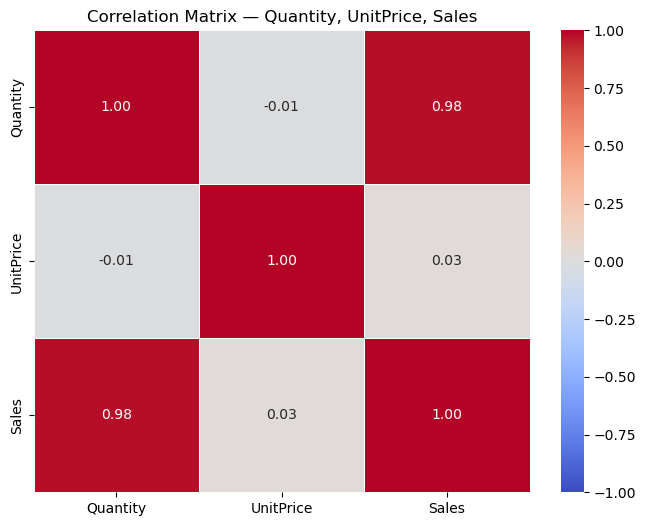

In [15]:
## Code Task 6 here
# Calculate the correlation matrix for numeric columns
correlation = df_filtered[['Quantity', 'UnitPrice', 'Sales']].corr()

# Display the correlation matrix as a table
display(correlation)

# Create a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation,
    annot=True,          # show the numbers in each cell
    cmap='coolwarm',     # blue = negative, red = positive
    fmt='.2f',           # 2 decimal places
    linewidths=0.5,
    vmin=-1, vmax=1      # force scale from -1 to +1
)
plt.title('Correlation Matrix — Quantity, UnitPrice, Sales')
plt.show()

## Findings

| Pair | Correlation | Interpretation |
|------|-------------|----------------|
| Quantity ↔ UnitPrice | -0.01 | No meaningful relationship |
| Quantity ↔ Sales | 0.98 | Very strong positive |
| UnitPrice ↔ Sales | 0.03 | No meaningful relationship |

### 1. Quantity ↔ Sales = 0.98
Almost perfectly positive. 

### 2. UnitPrice ↔ Sales = 0.03
Essentially no correlation. This is the more interesting finding:
a higher unit price does **not** predict higher revenue per line.
The likely reason is that cheap items are bought in bulk and
expensive items are bought singly, so the two effects cancel out.

### 3. Quantity ↔ UnitPrice = -0.01
No correlation. Price does not predict the number of units sold.

## Key Insight
The only strong relationship in the data is between Quantity and
Sales — but that is expected by definition. The more meaningful
finding is that **UnitPrice has almost no relationship with
Sales**, suggesting that price alone does not drive revenue in
this dataset.

## Task 7: Grouping and Aggregating
### Objective: Perform grouping and aggregation operations to summarise the data.

Instructions:

GroupBy operation: Group by Product_Category and calculate the total Sales per category.

Create a Pivot Table to show Sales by Country and Product_Category.

In [17]:
## Code Task 7 here

# Group by Product_Category and total Sales
sales_by_category = df_filtered.groupby('Product_Category')['Sales'].sum().reset_index()
sales_by_category = sales_by_category.sort_values(by='Sales', ascending=False)

display(sales_by_category)



In [18]:
# Pivot table: rows = Country, columns = Product_Category, values = Sales
pivot_table = df_filtered.pivot_table(
    values='Sales',
    index='Country',
    columns='Product_Category',
    aggfunc='sum'
)

# Reset index so Country becomes a regular column
pivot_table = pivot_table.reset_index()

display(pivot_table)

In [22]:
# Identify top 10 countries and top 10 categories
top_countries = (
    df_filtered.groupby('Country')['Sales']
    .sum()
    .nlargest(10)
    .index
)

top_categories = (
    df_filtered.groupby('Product_Category')['Sales']
    .sum()
    .nlargest(10)
    .index
)

# Build readable pivot table
pivot_clean = df_filtered[
    df_filtered['Country'].isin(top_countries) &
    df_filtered['Product_Category'].isin(top_categories)
].pivot_table(
    values='Sales',
    index='Country',
    columns='Product_Category',
    aggfunc='sum'
).fillna(0)

# Sort by total Sales descending, then reset index so Country shows
pivot_clean = pivot_clean.loc[pivot_clean.sum(axis=1).sort_values(ascending=False).index]
pivot_clean = pivot_clean.reset_index()

display(pivot_clean)

The GroupBy above summarised Sales by a single dimension
(Product_Category). A pivot table takes this further by grouping
on **two dimensions at once** — Country down the rows and
Product_Category across the columns — producing a grid that
shows Sales for every Country × Category combination.

Because the full pivot table would be ~170 columns wide (one per
category), I filtered it to the **top 10 countries × top 10
categories** using `.nlargest(10)`. This keeps the table readable
while preserving the most commercially significant data.

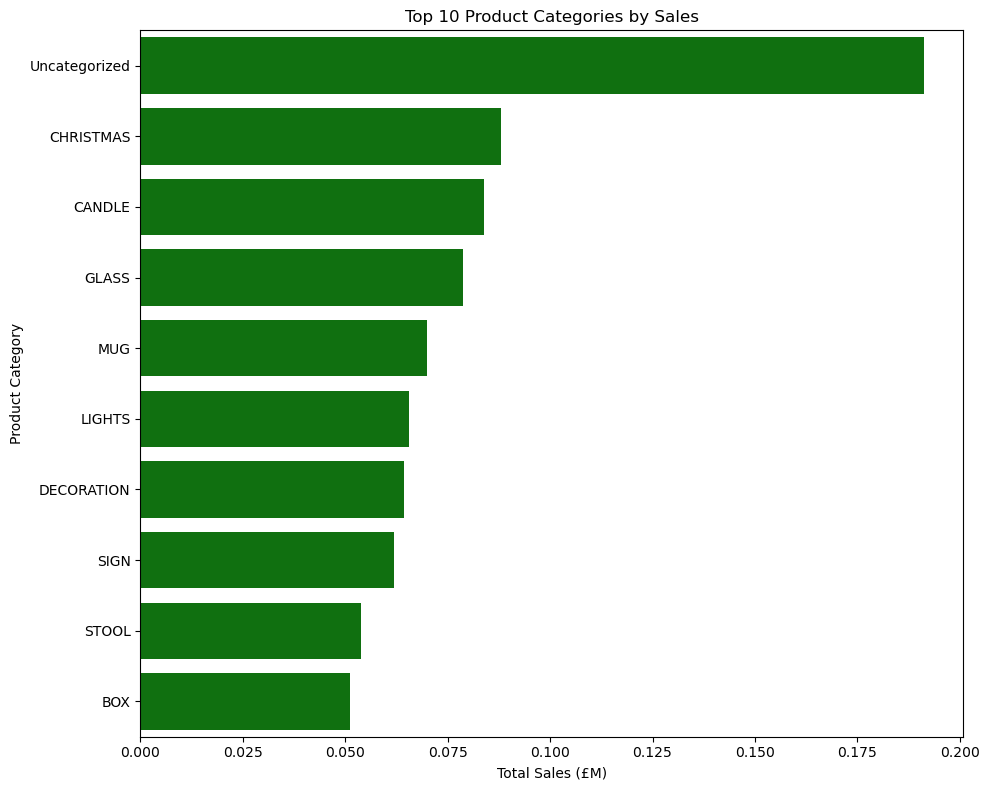

In [19]:
# Convert to millions for readability
sales_by_category_chart = sales_by_category.copy()
sales_by_category_chart['Sales'] = sales_by_category_chart['Sales'] / 1_000_000
sales_by_category_chart = sales_by_category_chart.head(10)   # top 10

plt.figure(figsize=(10, 8))
sns.barplot(x='Sales', y='Product_Category', data=sales_by_category_chart,
            color='green', orient='h')
plt.title('Top 10 Product Categories by Sales')
plt.xlabel('Total Sales (£M)')
plt.ylabel('Product Category')
plt.tight_layout()
plt.show()

The bar chart visualises the GroupBy result from Part 1, showing
total Sales for the top 10 product categories.

### Observations
- **"Uncategorized" is the largest bar by a wide margin (~£190K)**
  — more than double the next category. This confirms the data
  quality issue identified earlier.
- **CHRISTMAS, CANDLE, and GLASS** follow as the top real
  categories, each in the £75K–£90K range.
- **MUG, LIGHTS, DECORATION, and SIGN** form a middle tier
  (~£60K–£70K each).
- **STOOL and BOX** round out the top 10 (~£50K each).

The dominance of seasonal and home-décor categories (CHRISTMAS,
CANDLE, GLASS, MUG, DECORATION) confirms the business operates
as a **home-décor / giftware retailer**. The high ranking of
"CHRISTMAS" is consistent with the seasonal October/November
sales peaks identified in Task 4.

## Submission Guidelines:
Submit the Python notebook with all the tasks and visualisations.

Ensure that each task is clearly explained and that all steps are followed.

Include markdown explanations where necessary to explain your thought process.

Good work